In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet34_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet34_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth
100%|██████████| 83.3M/83.3M [00:00<00:00, 189MB/s]


Epoch 0/99
----------
train Loss: 0.7738 Acc: 0.7365
test Loss: 1.5420 Acc: 0.7280
Epoch 1/99
----------
train Loss: 0.4875 Acc: 0.8362
test Loss: 0.6541 Acc: 0.7520
Epoch 2/99
----------
train Loss: 0.4094 Acc: 0.8566
test Loss: 0.9290 Acc: 0.7440
Epoch 3/99
----------
train Loss: 0.3944 Acc: 0.8810
test Loss: 0.6321 Acc: 0.7760
Epoch 4/99
----------
train Loss: 0.2976 Acc: 0.9034
test Loss: 0.2802 Acc: 0.9040
Epoch 5/99
----------
train Loss: 0.3023 Acc: 0.8922
test Loss: 0.5346 Acc: 0.8760
Epoch 6/99
----------
train Loss: 0.2811 Acc: 0.8973
test Loss: 1.5511 Acc: 0.7160
Epoch 7/99
----------
train Loss: 0.2301 Acc: 0.9268
test Loss: 0.2331 Acc: 0.9280
Epoch 8/99
----------
train Loss: 0.2686 Acc: 0.9145
test Loss: 0.3790 Acc: 0.8680
Epoch 9/99
----------
train Loss: 0.2194 Acc: 0.9257
test Loss: 0.5208 Acc: 0.8400
Epoch 10/99
----------
train Loss: 0.2231 Acc: 0.9278
test Loss: 0.2822 Acc: 0.8880
Epoch 11/99
----------
train Loss: 0.1723 Acc: 0.9349
test Loss: 0.1236 Acc: 0.9560
Ep

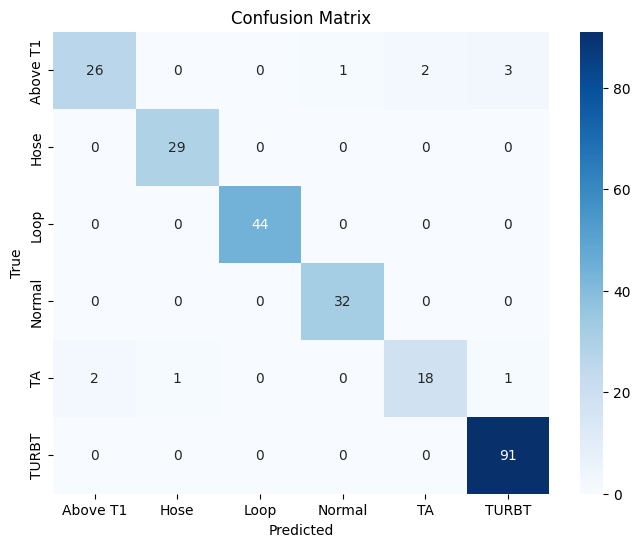

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import os

# 1. Define Dataset Path and Hyperparameters
data_dir = '/content/drive/MyDrive/BLC Dataset/WLI_split'
num_classes = 6
batch_size = 32
num_epochs = 100
learning_rate = 0.001
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Image Transforms
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

# 3. Load Dataset
image_datasets = {x: datasets.ImageFolder(root=f'{data_dir}/{x}', transform=data_transforms[x])
                  for x in ['train', 'test']}

dataloaders = {x: DataLoader(image_datasets[x], batch_size=batch_size, shuffle=True)
               for x in ['train', 'test']}

dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'test']}
class_names = image_datasets['train'].classes

# 4. Load Pretrained ResNet-34 Model and Modify for Classification
model = models.resnet34(pretrained=True)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, num_classes)  # Modify final layer for 6 classes
model = model.to(device)

# 5. Define Loss and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# 6. Training Loop with Model Saving
def train_model(model, dataloaders, criterion, optimizer, num_epochs=25, save_path='resnet34_weights.pth'):
    best_model_wts = model.state_dict()
    best_acc = 0.0

    for epoch in range(num_epochs):
        print(f'Epoch {epoch}/{num_epochs - 1}')
        print('-' * 10)

        for phase in ['train', 'test']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            # Save the model if accuracy improves
            if phase == 'test' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = model.state_dict()

    # Save the best model weights
    model.load_state_dict(best_model_wts)
    torch.save(model.state_dict(), save_path)
    print(f'Model weights saved to {save_path}')

    return model

save_path = '/content/resnet34_weights.pth'
model = train_model(model, dataloaders, criterion, optimizer, num_epochs, save_path)

# 7. Evaluation and Confusion Matrix
def evaluate_model(model, dataloaders):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloaders['test']:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            all_preds.append(preds.cpu().numpy())
            all_labels.append(labels.cpu().numpy())

    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)

    return all_labels, all_preds

labels, preds = evaluate_model(model, dataloaders)

# Classification Report
print("Classification Report:")
print(classification_report(labels, preds, target_names=class_names))

# Confusion Matrix
conf_matrix = confusion_matrix(labels, preds)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# 8. Download the model weights
from google.colab import files
files.download(save_path)
